# 05 — Credit Policy and Business Value

A credit model ranks risk; a **credit policy** turns that ranking into actions. This notebook shows
how approval rate, bad rate, loss capture, and simplified unit economics move together. The values
below are illustrative assumptions—not a recommendation for a real lender.

**Scope:** validation predictions from the leading XGBoost candidate are used to demonstrate policy
analysis. This does not change its status: Logistic Regression remains champion until governance
gates are complete. Outcomes are observed historical labels, so the analysis cannot identify how
applicants rejected by a past policy would have performed—a classic reject-inference limitation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Run this notebook from the project or notebook directory")


PROJECT_ROOT = find_project_root()
predictions = pd.read_csv(PROJECT_ROOT / "reports" / "notebook3_validation_predictions.csv")
MODEL_COLUMN = "xgboost_probability"
predictions[["TARGET", MODEL_COLUMN]].describe()

,TARGET,xgboost_probability
count,61502.000000,61502.000000
mean,0.080729,0.081002
std,0.272421,0.073997
min,0.000000,0.002241
25%,0.000000,0.031434
50%,0.000000,0.056736
75%,0.000000,0.104225
max,1.000000,0.683177


## 1. Risk deciles and rank ordering

The highest-risk decile should contain materially more defaults than the lowest-risk decile. A
monotonic pattern is a practical stability and usability check, not merely a presentation device.

In [2]:
analysis = predictions[["SK_ID_CURR", "TARGET", MODEL_COLUMN]].copy()
analysis["risk_decile"] = pd.qcut(
    analysis[MODEL_COLUMN].rank(method="first", ascending=False),
    10,
    labels=range(1, 11),
)
deciles = (
    analysis.groupby("risk_decile", observed=True)
    .agg(
        applicants=("TARGET", "size"),
        defaults=("TARGET", "sum"),
        observed_default_rate=("TARGET", "mean"),
        mean_predicted_pd=(MODEL_COLUMN, "mean"),
    )
    .reset_index()
)
deciles["share_of_all_defaults"] = deciles["defaults"] / deciles["defaults"].sum()
deciles["cumulative_defaults_captured"] = deciles["share_of_all_defaults"].cumsum()
deciles.style.format(
    {
        "observed_default_rate": "{:.2%}",
        "mean_predicted_pd": "{:.2%}",
        "share_of_all_defaults": "{:.2%}",
        "cumulative_defaults_captured": "{:.2%}",
    }
)

,risk_decile,applicants,defaults,observed_default_rate,mean_predicted_pd,share_of_all_defaults,cumulative_defaults_captured
0,1,6151,1618,26.30%,25.62%,32.59%,32.59%
1,2,6150,865,14.07%,14.44%,17.42%,50.01%
2,3,6150,658,10.70%,10.49%,13.25%,63.26%
3,4,6150,480,7.80%,8.08%,9.67%,72.93%
4,5,6150,376,6.11%,6.37%,7.57%,80.50%
5,6,6150,329,5.35%,5.08%,6.63%,87.13%
6,7,6150,223,3.63%,4.03%,4.49%,91.62%
7,8,6150,185,3.01%,3.15%,3.73%,95.35%
8,9,6150,139,2.26%,2.34%,2.80%,98.15%
9,10,6151,92,1.50%,1.41%,1.85%,100.00%


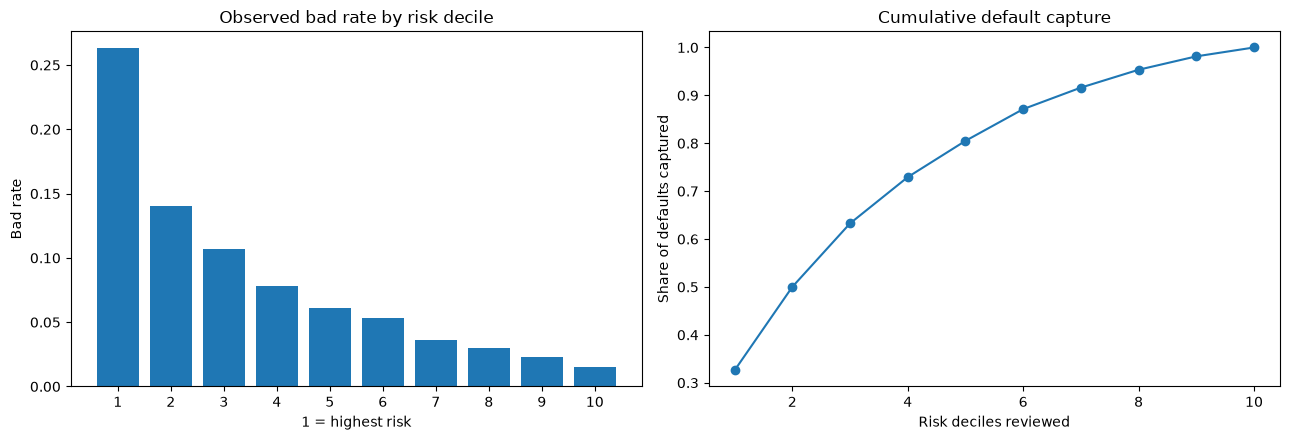

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(deciles["risk_decile"].astype(str), deciles["observed_default_rate"])
axes[0].set(title="Observed bad rate by risk decile", xlabel="1 = highest risk", ylabel="Bad rate")
axes[1].plot(
    deciles["risk_decile"], deciles["cumulative_defaults_captured"], marker="o"
)
axes[1].set(
    title="Cumulative default capture",
    xlabel="Risk deciles reviewed",
    ylabel="Share of defaults captured",
)
plt.tight_layout()
plt.show()

## 2. Approval frontier

For each target approval rate, approve applicants below the corresponding predicted-PD cutoff. We
then measure the realized default rate among approved applicants and the share of all defaults kept
out of the approved book.

In [4]:
policy_rows = []
for target_approval in np.arange(0.50, 0.96, 0.05):
    threshold = float(analysis[MODEL_COLUMN].quantile(target_approval))
    approved = analysis[MODEL_COLUMN] < threshold
    declined = ~approved
    policy_rows.append(
        {
            "target_approval_rate": target_approval,
            "threshold": threshold,
            "actual_approval_rate": approved.mean(),
            "approved_bad_rate": analysis.loc[approved, "TARGET"].mean(),
            "declined_bad_rate": analysis.loc[declined, "TARGET"].mean(),
            "defaults_captured_by_declines": (
                analysis.loc[declined, "TARGET"].sum() / analysis["TARGET"].sum()
            ),
        }
    )

frontier = pd.DataFrame(policy_rows)
frontier.style.format(
    {
        "target_approval_rate": "{:.0%}",
        "threshold": "{:.3f}",
        "actual_approval_rate": "{:.1%}",
        "approved_bad_rate": "{:.2%}",
        "declined_bad_rate": "{:.2%}",
        "defaults_captured_by_declines": "{:.1%}",
    }
)

,target_approval_rate,threshold,actual_approval_rate,approved_bad_rate,declined_bad_rate,defaults_captured_by_declines
0,50%,0.057,50.0%,3.15%,13.00%,80.5%
1,55%,0.063,55.0%,3.38%,13.81%,77.0%
2,60%,0.071,60.0%,3.64%,14.72%,72.9%
3,65%,0.081,65.0%,3.89%,15.84%,68.7%
4,70%,0.091,70.0%,4.24%,17.02%,63.3%
5,75%,0.104,75.0%,4.60%,18.48%,57.2%
6,80%,0.121,80.0%,5.04%,20.19%,50.0%
7,85%,0.143,85.0%,5.52%,22.56%,41.9%
8,90%,0.175,90.0%,6.05%,26.30%,32.6%
9,95%,0.233,95.0%,6.80%,32.25%,20.0%


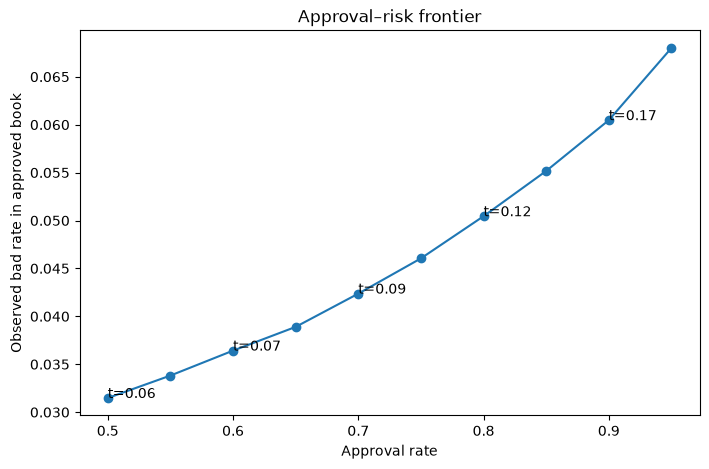

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(frontier["actual_approval_rate"], frontier["approved_bad_rate"], marker="o")
for _, row in frontier.iloc[::2].iterrows():
    ax.annotate(f"t={row['threshold']:.2f}", (row["actual_approval_rate"], row["approved_bad_rate"]))
ax.set(xlabel="Approval rate", ylabel="Observed bad rate in approved book")
ax.set_title("Approval–risk frontier")
plt.show()

## 3. Illustrative unit economics

A simple realized-value model makes assumptions visible:

- performing approved loan contribution: **700 currency units**;
- default exposure: **10,000**;
- loss given default: **45%**;
- declined applications contribute zero.

Real pricing, prepayment, funding costs, recovery timing, operating cost, and selection effects are
omitted. This is useful for sensitivity analysis, not a business case.

In [6]:
MARGIN_PER_GOOD_LOAN = 700
EXPOSURE_AT_DEFAULT = 10_000
LOSS_GIVEN_DEFAULT = 0.45

economics = []
for _, policy in frontier.iterrows():
    approved = analysis[MODEL_COLUMN] < policy["threshold"]
    good_loans = int(((analysis["TARGET"] == 0) & approved).sum())
    bad_loans = int(((analysis["TARGET"] == 1) & approved).sum())
    contribution = (
        good_loans * MARGIN_PER_GOOD_LOAN
        - bad_loans * EXPOSURE_AT_DEFAULT * LOSS_GIVEN_DEFAULT
    )
    economics.append(
        {
            "approval_rate": approved.mean(),
            "good_loans": good_loans,
            "bad_loans": bad_loans,
            "illustrative_contribution": contribution,
        }
    )

economics = pd.DataFrame(economics)
best_policy = economics.loc[economics["illustrative_contribution"].idxmax()]
economics.style.format(
    {"approval_rate": "{:.0%}", "illustrative_contribution": "{:,.0f}"}
).highlight_max(subset=["illustrative_contribution"], color="#d1fae5")

,approval_rate,good_loans,bad_loans,illustrative_contribution
0,50%,29783,968,"16,492,100"
1,55%,32682,1144,"17,729,400"
2,60%,35557,1344,"18,841,900"
3,65%,38421,1555,"19,897,200"
4,70%,41227,1824,"20,650,900"
5,75%,44002,2124,"21,243,400"
6,80%,46719,2482,"21,534,300"
7,85%,49392,2884,"21,596,400"
8,90%,52004,3347,"21,341,300"
9,95%,54453,3973,"20,238,600"


In [7]:
print(
    "Illustrative optimum: "
    f"approval={best_policy['approval_rate']:.0%}, "
    f"contribution={best_policy['illustrative_contribution']:,.0f}, "
    f"good loans={best_policy['good_loans']:,.0f}, "
    f"bad loans={best_policy['bad_loans']:,.0f}"
)

Illustrative optimum: approval=85%, contribution=21,596,400, good loans=49,392, bad loans=2,884


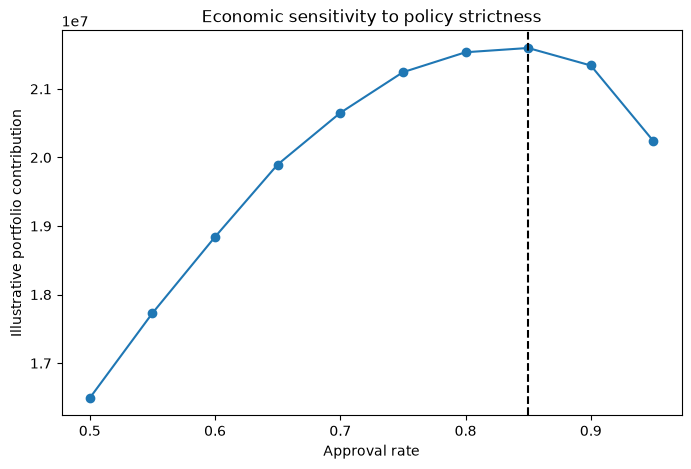

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(economics["approval_rate"], economics["illustrative_contribution"], marker="o")
ax.axvline(best_policy["approval_rate"], linestyle="--", color="black")
ax.set(xlabel="Approval rate", ylabel="Illustrative portfolio contribution")
ax.set_title("Economic sensitivity to policy strictness")
plt.show()

## Policy conclusion

The model creates useful risk separation, but the “best” cutoff changes with economics, risk
appetite, fairness constraints, capacity, and regulation. Model validation approves a score;
credit governance separately approves how that score is used.
Under the stated assumptions, the validation illustration peaks near an **85% approval rate** with
a contribution of roughly **21.6 million currency units**. That number is a scenario output, not a
forecast, because it applies constant exposure and loss assumptions to observed accepted outcomes.

The economic maximum shown above is conditional on four simplified assumptions and should be read
as a sensitivity demonstration. A production policy would model exposure-specific EAD, LGD and
maturity, interest and funding costs, recovery timing, prepayment, acquisition/operations cost,
affordability rules, capital constraints, fairness, uncertainty, and reject inference. Thresholds
should then be approved, versioned, monitored, and stress-tested independently of the model artifact.